# 03. 시장 매력도 스크리닝과 추천 3곳

- **목적**: 이슈 트리의 A 갈래("지금 이 상권은 매력적인가?")를 검증하고 2호점 후보 3곳을 고름
- **검증할 가설** (`docs/02_가설_작업계획.md`)
  - H1 수요: 서울 전체는 정체해도, 카페 손님이 늘어난 상권이 있다
  - H2 경쟁: 그중 카페 한 곳이 받는 손님(몫)이 커졌고 지금도 많은 상권이 있다
  - H3 매출: 몫이 커진 상권 중 카페 한 곳의 매출도 높은 상권이 있다
  - H4 비용: 상위 후보의 임대료는 감당할 수 있는 수준(서울 평균의 1.5배 이하)이다
- **데이터 출처**: DB 표 `커피_매출`, `커피_점포`, `영역` (`02` 출력), `sql/02_추천지표.sql`,
  `data/raw/임대동향 지역별 임대료(2026년2분기)_소규모 상가.csv` (한국부동산원)
- **출력**: DB 표 `추천_지표`, `data/processed/추천_후보.csv`, `docs/images/matrix.png`, `docs/images/recommend_top3.png`

## 설정

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import text

sys.path.append("..")  # notebooks/에서 실행하므로 프로젝트 루트의 src를 import 경로에 추가
from src.db import get_engine
from src.viz import quarter_label, set_korean_font

pd.set_option("display.max_columns", 30)
set_korean_font()

In [2]:
ENV_PATH = Path("../.env")
METRIC_SQL_PATH = Path("../sql/02_추천지표.sql")
RENT_PATH = Path("../data/raw/임대동향 지역별 임대료(2026년2분기)_소규모 상가.csv")
OUT_DIR = Path("../data/processed")
IMAGE_DIR = Path("../docs/images")

MIN_STORES = 10    # 2년 전·최근 모두 평균 카페 수가 이 이상인 상권만 봄
BREAK_LIMIT = 1.5  # 한 분기 변화가 이 배수를 넘으면 데이터 단절로 봄 (01 4절)
RENT_LIMIT = 1.5   # 임대료가 서울 평균의 이 배수를 넘으면 소규모 브랜드가 감당하기 어렵다고 봄
N_PICK = 3

# 임대료 조사 상권과 이름이 같은(같은 곳을 가리키는) 상권
SURVEY_NAME = {"3120022": "시청", "3120007": "북촌", "3120243": "천호", "3120069": "상봉역"}
# 이름이 같은 조사 상권이 없으면 자치구가 속한 권역의 평균을 씀 (나머지 자치구는 "기타" 권역)
REGION_BY_GU = {"종로구": "도심", "중구": "도심", "강남구": "강남", "서초구": "강남",
                "영등포구": "영등포신촌", "마포구": "영등포신촌", "서대문구": "영등포신촌"}

## 1. SQL로 지표 계산

- `sql/02_추천지표.sql`을 실행해 상권마다 한 행인 표 `추천_지표`를 만듦
- 계산 방법은 SQL 파일 주석과 `docs/지표_정의서.md` 참고

In [3]:
engine = get_engine(ENV_PATH)
statements = [s for s in METRIC_SQL_PATH.read_text(encoding="utf-8").split(";") if s.strip()]
with engine.begin() as conn:
    for statement in statements:
        conn.execute(text(statement))

metrics = pd.read_sql('SELECT * FROM "추천_지표"', engine).set_index("상권_코드")
print("분석 대상 상권:", len(metrics))
metrics["상권_구분_코드_명"].value_counts()

분석 대상 상권: 992


상권_구분_코드_명
골목상권    627
발달상권    243
전통시장    116
관광특구      6
Name: count, dtype: int64

In [4]:
metrics.describe().round(1)

,점포_2년전,점포_최근,손님_2년_증가율,점포_2년_증가율,점포당_손님_2년_증가율,점포당_월_손님,점포당_월_매출,객단가_2년_변화율,최대_분기_변화
count,992.0,992.0,992.0,992.0,992.0,992.0,992.0,992.0,992.0
mean,21.7,20.8,12.5,-3.9,16.9,3054.8,22792322.1,6.8,3.5
std,31.6,30.5,175.4,17.0,158.2,3478.0,25637543.5,55.9,46.4
min,3.0,3.0,-98.8,-55.6,-98.3,5.0,57740.0,-69.8,1.1
25%,7.0,7.0,-22.7,-14.3,-20.0,797.0,6939924.8,-6.4,1.3
50%,12.0,10.9,-7.5,-4.1,-2.2,1970.5,14598213.0,3.4,1.4
75%,21.8,21.1,11.1,4.8,20.4,4165.5,30369786.5,11.9,1.7
max,341.0,333.3,4144.1,91.7,3672.6,40037.0,322446929.0,1520.7,1460.7


### 관찰
- 분석 대상 992곳: 골목상권 627, 발달상권 243, 전통시장 116, 관광특구 6
- 중앙값 기준 손님 2년 증가율 −7.5%, 카페 수 2년 증가율 −4.1% → 절반 넘는 상권은 손님이 줄었음
- 손님 2년 증가율 최댓값 +4,144%, 최대 분기 변화 최댓값 약 1,461배 → 극단값이 있으므로 거르기가 필요

## 2. 거르기 (H1 수요, H2 경쟁)

| 묶음 | 단계 | 조건 | 이유 |
|---|---|---|---|
| 분석 범위 | 1 | 관광특구 제외 | 영역이 넓어 다른 상권과 겹침 → 같은 손님을 두 번 세게 됨 |
| 데이터 신뢰도 | 2 | 2년 전·최근 모두 평균 카페 10개 이상 | 카페가 적으면 한두 곳의 변화로 숫자가 크게 흔들림 |
| 데이터 신뢰도 | 3 | 최근 12개 분기에 데이터 단절 없음 | 한 분기에 1.5배 넘게 변하면 계절로 설명되지 않음(`01` 4절) |
| H1 수요 | 4 | 손님 2년 증가율 > 0 | 상권 전체의 카페 손님이 늘어야 함 |
| H2 경쟁 | 5 | 점포당 손님 2년 증가율 > 0 | 카페가 손님보다 빨리 늘었다면 한 곳의 몫은 줄어든 것 |

상권마다 처음 걸린 단계에서만 빠지므로, 빠진 상권 수를 모두 더하면 분석 대상 수와 맞음(겹치지 않음).

In [5]:
def apply_filters(metrics: pd.DataFrame, break_limit: float) -> tuple[pd.DataFrame, pd.Series]:
    """거르기 5단계를 차례로 적용함. (남은 상권, 단계별 남은 상권 수)를 돌려줌."""
    steps = {
        "1 관광특구 제외": metrics["상권_구분_코드_명"] != "관광특구",
        "2 카페 10개 이상": (metrics["점포_2년전"] >= MIN_STORES) & (metrics["점포_최근"] >= MIN_STORES),
        "3 단절 없음": metrics["최대_분기_변화"] <= break_limit,
        "4 손님 증가": metrics["손님_2년_증가율"] > 0,
        "5 점포당 손님 증가": metrics["점포당_손님_2년_증가율"] > 0,
    }
    keep = pd.Series(True, index=metrics.index)
    funnel = {"0 분석 대상": len(metrics)}
    for name, condition in steps.items():
        keep = keep & condition  # 앞 단계를 통과한 상권 중에서 다시 거름
        funnel[name] = int(keep.sum())
    return metrics.loc[keep].copy(), pd.Series(funnel, name="남은 상권 수")

In [6]:
candidates, funnel = apply_filters(metrics, BREAK_LIMIT)
funnel.to_frame().assign(빠진_상권=lambda d: d["남은 상권 수"].diff().fillna(0).astype(int))

,남은 상권 수,빠진_상권
0 분석 대상,992,0
1 관광특구 제외,986,-6
2 카페 10개 이상,521,-465
3 단절 없음,364,-157
4 손님 증가,111,-253
5 점포당 손님 증가,94,-17


In [7]:
# 4단계(손님 증가)와 5단계(점포당 손님 증가)가 서로 다른 상권을 거르는지 확인
pd.crosstab(metrics["손님_2년_증가율"] > 0, metrics["점포당_손님_2년_증가율"] > 0,
            rownames=["손님 증가"], colnames=["점포당 손님 증가"])

점포당 손님 증가,False,True
손님 증가,,
False,488,148
True,41,315


### 관찰과 판정
- 992 → 986 → 521 → 364 → 111 → **94곳**. 빠진 상권 6 + 465 + 157 + 253 + 17 = 898곳, 남은 94곳과 합치면 992곳
- 교차표: 손님은 줄었는데 점포당 손님은 늘어난 상권 148곳, 손님은 늘었는데 점포당 손님은 줄어든 상권 41곳
  → 4단계와 5단계는 서로 다른 상권을 거름. 둘 중 하나만 쓰면 이 상권들이 남음
- **H1 판정: 채택.** 데이터 신뢰도 조건을 통과한 364곳 중 111곳(30%)은 손님이 늘었음
- **H2 판정: 채택.** 그중 94곳은 카페 한 곳이 받는 손님도 늘었음

## 3. 점수 (H2 경쟁, H3 매출)

- 남은 후보 안에서 세 지표를 백분위(0~100)로 바꾼 뒤 평균을 냄

| 점수 | 지표 | 이슈 트리 갈래 |
|---|---|---|
| 성장 점수 | 점포당 손님 2년 증가율 | A2 경쟁: 카페 한 곳의 몫이 커지고 있는가 |
| 손님 점수 | 점포당 월 손님 | A2 경쟁: 지금도 카페 한 곳이 손님을 많이 받는가 |
| 수익 점수 | 점포당 월 매출 | A3 수익성(매출): 카페 한 곳이 돈을 버는가 |

- 백분위로 바꾸는 이유: 증가율(%), 손님(건), 매출(원)은 단위가 달라서 그대로 더할 수 없음
- `rank(pct=True)`: 후보 중 그 값보다 작거나 같은 상권의 비율 (가장 큰 값 = 100)
- 세 점수는 같은 비중(1/3씩): 어느 갈래가 더 중요하다는 근거가 없으므로

In [8]:
def score(candidates: pd.DataFrame) -> pd.DataFrame:
    """성장·손님·수익 점수와 셋의 평균인 점수를 붙이고 점수 순으로 정렬함."""
    scored = candidates.copy()
    scored["성장_점수"] = scored["점포당_손님_2년_증가율"].rank(pct=True) * 100
    scored["손님_점수"] = scored["점포당_월_손님"].rank(pct=True) * 100
    scored["수익_점수"] = scored["점포당_월_매출"].rank(pct=True) * 100
    scored["점수"] = scored[["성장_점수", "손님_점수", "수익_점수"]].mean(axis=1)
    return scored.sort_values("점수", ascending=False)

In [9]:
scored = score(candidates)

show_cols = ["상권_코드_명", "자치구_코드_명", "점포_최근", "손님_2년_증가율", "점포_2년_증가율",
             "점포당_손님_2년_증가율", "점포당_월_손님", "점포당_월_매출", "성장_점수", "손님_점수", "수익_점수", "점수"]
scored[show_cols].head(10).round(1)

,상권_코드_명,자치구_코드_명,점포_최근,손님_2년_증가율,점포_2년_증가율,점포당_손님_2년_증가율,점포당_월_손님,점포당_월_매출,성장_점수,손님_점수,수익_점수,점수
상권_코드,,,,,,,,,,,,
3120220,대치역,강남구,11.3,24.5,-29.7,77.1,17019.0,81533774.0,98.9,98.9,96.8,98.2
3120238,방이역,송파구,16.8,46.6,-4.3,53.2,26129.0,109455986.0,88.8,100.0,100.0,96.3
3120225,잠실새내역(신천),송파구,73.8,4.6,-15.5,23.7,10600.0,72013766.0,61.7,96.8,92.6,83.7
3120227,잠실역,송파구,140.0,13.3,-9.1,24.6,7308.0,60913650.0,62.8,89.4,86.2,79.4
3120022,북창동(시청역_6번),중구,35.0,20.7,-1.4,22.5,7297.0,70406554.0,58.5,88.3,91.5,79.4
3120007,북촌(안국역),종로구,88.5,25.1,6.0,18.0,7150.0,86116169.0,46.8,86.2,98.9,77.3
3120243,천호역,강동구,49.8,80.4,7.0,68.6,6375.0,33408057.0,96.8,77.7,56.4,77.0
3110409,창동역 2번,도봉구,11.3,2.0,-33.8,54.2,6044.0,39625518.0,90.4,75.5,61.7,75.9
3120108,신정네거리역,양천구,28.0,53.4,-11.1,72.5,5180.0,43695004.0,97.9,61.7,68.1,75.9


### 2×2 매트릭스: 성장 × 수익

- 가로 = 카페 한 곳의 손님 증가율(성장), 세로 = 카페 한 곳의 월 매출(수익), 점선 = 후보 94곳의 중앙값
- 오른쪽 위 칸이 "몫이 커지고 돈도 되는" 상권

In [10]:
def plot_matrix(scored: pd.DataFrame, picks: pd.Index, excluded: pd.Index) -> None:
    """후보를 성장 × 수익 평면에 찍고 추천·제외 상권에 이름을 붙임."""
    x = scored["점포당_손님_2년_증가율"]
    y = scored["점포당_월_매출"] / 1e4  # 만 원
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(x, y, color="lightgrey", label=f"후보 {len(scored)}곳")
    ax.scatter(x[excluded], y[excluded], color="grey", label="임대료로 제외")
    ax.scatter(x[picks], y[picks], color="darkred", s=80, label="추천 3곳")
    for code in picks.append(excluded):
        ax.annotate(scored.at[code, "상권_코드_명"], (x[code], y[code]), xytext=(5, 5), textcoords="offset points")
    ax.axvline(x.median(), color="grey", linestyle="--", linewidth=1)
    ax.axhline(y.median(), color="grey", linestyle="--", linewidth=1)
    ax.set_xlabel("카페 한 곳의 손님 2년 증가율 (%)")
    ax.set_ylabel("카페 한 곳의 월 매출 (만 원)")
    ax.set_title("성장 × 수익 매트릭스 (점선 = 후보 중앙값)")
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.savefig(IMAGE_DIR / "matrix.png", dpi=150)
    plt.show()

## 4. 자치구마다 1곳, 임대료 확인 (H4 비용)

- 점수 순으로 내려가며 **자치구마다 1곳만** 남김 → 같은 동네 두 곳을 추천하지 않으려고
- 남은 상권마다 한국부동산원 소규모 상가 임대료(2026년 2분기, 천원/㎡)를 붙임
  - 조사 상권과 이름이 같은 곳(예: 천호역 → 천호)은 그 값
  - 없으면 자치구가 속한 권역(도심·강남·영등포신촌·기타)의 평균
- 서울 평균(52.8)의 **1.5배를 넘으면 제외**하고, 통과한 곳 중 위에서 3곳을 추천

In [11]:
rent_table = pd.read_csv(RENT_PATH, encoding="cp949", skiprows=3, header=None,
                         names=["번호", "시", "권역", "지역", "임대료"])
rent = rent_table.set_index("지역")["임대료"].astype(float)
SEOUL_RENT = rent["서울"]
print("서울 평균 임대료:", SEOUL_RENT, "천원/㎡ | 조사 지역", len(rent), "곳")

서울 평균 임대료: 52.8 천원/㎡ | 조사 지역 64 곳


In [12]:
def add_rent(shortlist: pd.DataFrame) -> pd.DataFrame:
    """임대료, 임대료 기준(조사 상권 또는 권역 평균), 서울 평균 대비 배수, 통과 여부를 붙임."""
    out = shortlist.copy()
    basis = [SURVEY_NAME.get(code, REGION_BY_GU.get(gu, "기타"))
             for code, gu in zip(out.index, out["자치구_코드_명"])]
    out["임대료_기준"] = [b if code in SURVEY_NAME else f"{b} 권역 평균" for code, b in zip(out.index, basis)]
    out["임대료"] = [rent[b] for b in basis]
    out["임대료_배수"] = out["임대료"] / SEOUL_RENT
    out["임대료_통과"] = out["임대료_배수"] <= RENT_LIMIT
    return out


def pick_top(scored: pd.DataFrame, n: int) -> tuple[pd.DataFrame, pd.DataFrame]:
    """자치구마다 1곳 → 임대료 확인 → 통과한 곳 중 위에서 n곳. (확인한 목록, 추천)을 돌려줌."""
    shortlist = add_rent(scored.drop_duplicates("자치구_코드_명"))
    picks = shortlist.loc[shortlist["임대료_통과"]].head(n)
    checked = shortlist.loc[: picks.index[-1]]  # 마지막 추천 상권까지 확인한 상권
    return checked, picks

In [13]:
checked, top3 = pick_top(scored, N_PICK)
rent_cols = ["상권_코드_명", "자치구_코드_명", "점수", "임대료_기준", "임대료", "임대료_배수", "임대료_통과"]
checked[rent_cols].round(2)

,상권_코드_명,자치구_코드_명,점수,임대료_기준,임대료,임대료_배수,임대료_통과
상권_코드,,,,,,,
3120220,대치역,강남구,98.23,강남 권역 평균,64.6,1.22,True
3120238,방이역,송파구,96.28,기타 권역 평균,45.1,0.85,True
3120022,북창동(시청역_6번),중구,79.43,시청,97.1,1.84,False
3120007,북촌(안국역),종로구,77.30,북촌,100.9,1.91,False
3120243,천호역,강동구,76.95,천호,57.6,1.09,True


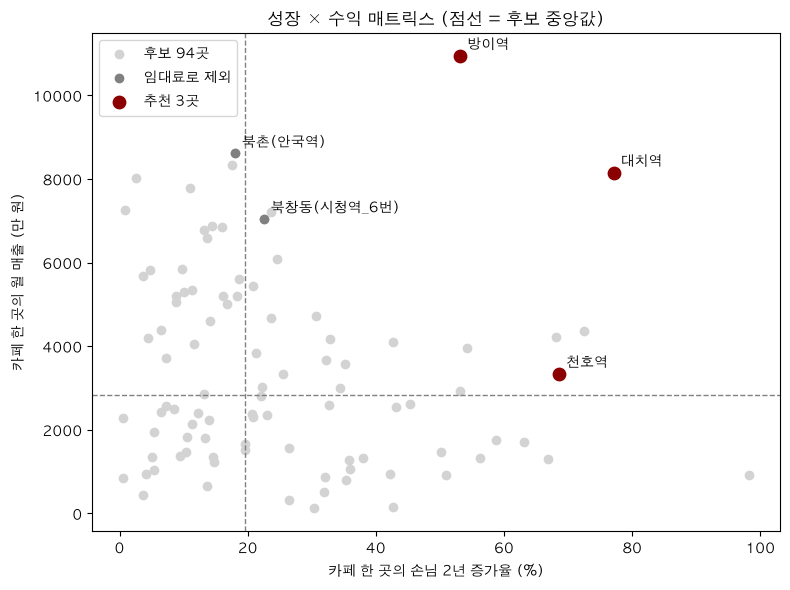

In [14]:
excluded = checked.index[~checked["임대료_통과"]]
plot_matrix(scored, top3.index, excluded)

### 관찰과 판정
- 1위 대치역(강남구) 98.2점, 2위 방이역(송파구) 96.3점
- 3·4위 잠실새내역·잠실역은 방이역과 같은 송파구라서 다음 단계에서 빠짐
- 북창동(시청역_6번)·북촌(안국역)은 매출(수익 점수 91.5·98.9)은 높지만 성장 점수가 58.5·46.8로 낮음
- 임대료 확인 결과
  - 북창동(조사 상권 '시청') 97.1천원/㎡ = 서울 평균의 1.84배, 북촌 100.9천원/㎡ = 1.91배 → 기준(1.5배) 초과로 제외
  - 대치역 1.22배(강남 권역 평균), 방이역 0.85배(기타 권역 평균), 천호역 1.09배(조사 상권 '천호') → 통과
- 매트릭스: 추천 3곳 모두 오른쪽 위 칸(성장·수익 모두 후보 중앙값 이상). 임대료로 빠진 두 곳은 성장이 중앙값 근처
- **H3 판정: 채택.** 방이역은 카페 한 곳의 월 매출 1억 946만 원으로 후보 1위, 대치역 8,153만 원으로 4위
  - 천호역은 3,341만 원으로 42위 → 중앙값(2,834만 원)은 넘지만 세 곳 중 수익성이 가장 약함
- **H4 판정: 부분 채택.** 상위 5곳 중 3곳만 통과. 도심 상권은 임대료 때문에 소규모 브랜드에 맞지 않음
  - 대치역·방이역은 이름이 같은 조사 상권이 없어 권역 평균을 썼으므로 실제 매물 임대료 확인 필요

## 5. 민감도: 판단 기준을 바꾸면 결과가 바뀌는가?

- 결과가 특정 기준 하나에 달려 있다면 보고서에 밝혀야 함
- 단절 기준(1.5배)은 결과를 본 뒤 정했으므로, 처음 생각했던 2배 기준과 비교

In [15]:
candidates_2x, funnel_2x = apply_filters(metrics, 2)
checked_2x, top3_2x = pick_top(score(candidates_2x), N_PICK)
pd.DataFrame({"1.5배 기준": funnel, "2배 기준": funnel_2x})

,1.5배 기준,2배 기준
0 분석 대상,992,992
1 관광특구 제외,986,986
2 카페 10개 이상,521,521
3 단절 없음,364,467
4 손님 증가,111,165
5 점포당 손님 증가,94,146


In [16]:
checked_2x[rent_cols + ["최대_분기_변화"]].round(2)

,상권_코드_명,자치구_코드_명,점수,임대료_기준,임대료,임대료_배수,임대료_통과,최대_분기_변화
상권_코드,,,,,,,,
3120084,공릉역,노원구,97.03,기타 권역 평균,45.1,0.85,True,1.51
3120220,대치역,강남구,96.12,강남 권역 평균,64.6,1.22,True,1.41
3120238,방이역,송파구,93.26,기타 권역 평균,45.1,0.85,True,1.48


In [17]:
# 2배 기준에서만 뽑힌 상권의 분기별 손님(천 건)
history_sql = """
SELECT m."기준_년분기_코드" AS 분기, m."상권_코드", m."당월_매출_건수" AS 건수,
       m."당월_매출_금액" AS 금액, p."전체_점포_수" AS 점포
FROM "커피_매출" m JOIN "커피_점포" p USING ("기준_년분기_코드", "상권_코드")
ORDER BY 분기
"""
history = pd.read_sql(history_sql, engine)

only_2x = top3_2x.index.difference(top3.index)
recent = history.loc[history["상권_코드"].isin(only_2x) & (history["분기"] >= "20233")]
recent.pivot(index="상권_코드", columns="분기", values="건수").div(1e3).round(1).rename(index=metrics["상권_코드_명"])

분기,20233,20234,20241,20242,20243,20244,20251,20252,20253,20254,20261,20262
상권_코드,,,,,,,,,,,,
공릉역,129.6,106.5,95.2,143.8,108.8,121.4,103.4,138.3,188.7,164.8,171.0,187.2


### 관찰
- 2배 기준이면 거르기 후보는 146곳, 추천은 **공릉역, 대치역, 방이역**
- 대치역·방이역은 두 기준 모두에서 추천됨 → 이 두 곳은 기준에 흔들리지 않음
- 세 번째 자리만 천호역 ↔ 공릉역으로 바뀜
  - 공릉역의 최대 분기 변화는 1.51배(2024년 1분기 9.5만 → 2분기 14.4만 건)로 기준을 아주 조금 넘음
  - 2분기는 원래 손님이 느는 분기(서울 +18.6%)라서 실제 성장일 수도 있음 → 천호역과 함께 현장 확인 대상으로 제시

## 6. 추천 3곳의 분기별 손님과 카페 수

- 2년 증가율이 한두 분기의 일이 아니라 꾸준한 흐름인지 그래프로 확인

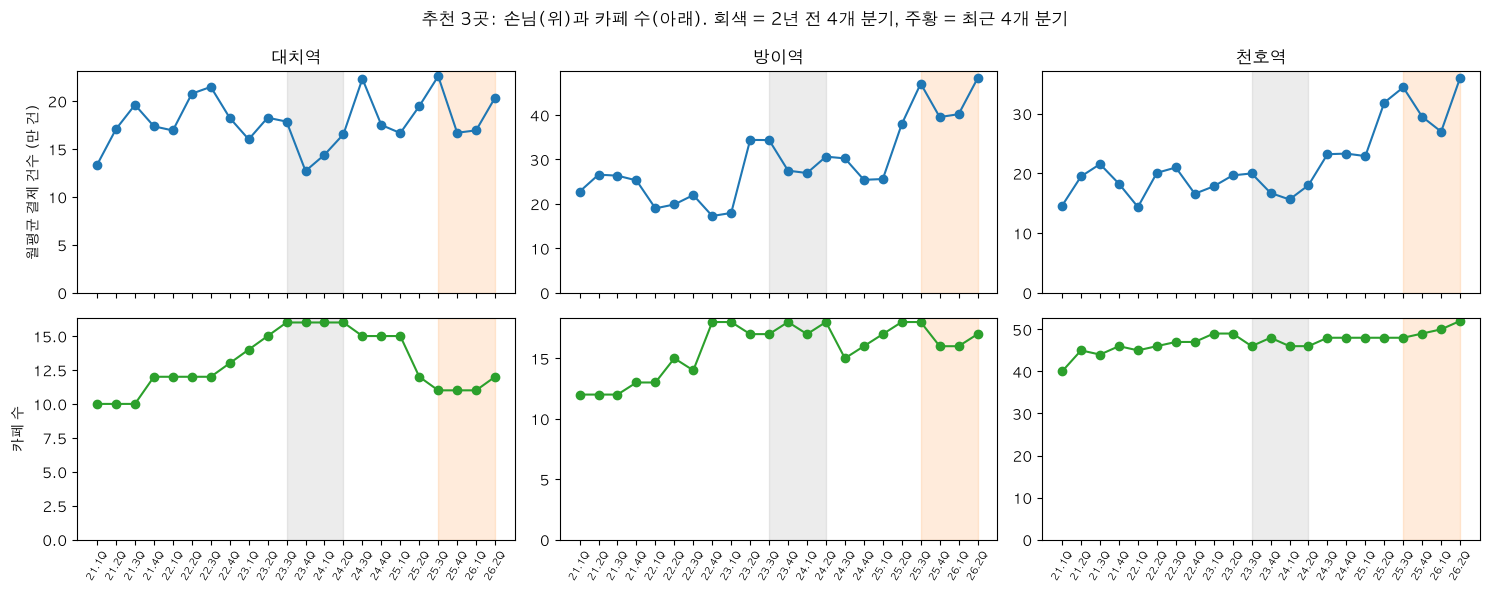

In [18]:
fig, axes = plt.subplots(2, N_PICK, figsize=(15, 6), sharex=True)
for col, code in enumerate(top3.index):
    one = history.loc[history["상권_코드"] == code]
    x = [quarter_label(q) for q in one["분기"]]
    axes[0, col].plot(x, one["건수"] / 1e4, marker="o")
    axes[0, col].set_title(top3.at[code, "상권_코드_명"])
    axes[1, col].plot(x, one["점포"], marker="o", color="tab:green")
    axes[1, col].tick_params(axis="x", labelrotation=60, labelsize=7)
    for row in range(2):
        axes[row, col].set_ylim(bottom=0)
        axes[row, col].axvspan("23.3Q", "24.2Q", color="grey", alpha=0.15)  # 2년 전 4개 분기
        axes[row, col].axvspan("25.3Q", "26.2Q", color="tab:orange", alpha=0.15)  # 최근 4개 분기
axes[0, 0].set_ylabel("월평균 결제 건수 (만 건)")
axes[1, 0].set_ylabel("카페 수")
plt.suptitle("추천 3곳: 손님(위)과 카페 수(아래). 회색 = 2년 전 4개 분기, 주황 = 최근 4개 분기")
plt.tight_layout()
plt.savefig(IMAGE_DIR / "recommend_top3.png", dpi=150)
plt.show()

In [19]:
# 추천 3곳의 객단가 변화 (위험 점검용, 점수에는 쓰지 않음)
top3[["상권_코드_명", "점포당_월_매출", "객단가_2년_변화율"]]

,상권_코드_명,점포당_월_매출,객단가_2년_변화율
상권_코드,,,
3120220,대치역,81533774.0,9.0
3120238,방이역,109455986.0,-22.2
3120243,천호역,33408057.0,-9.9


### 관찰
- 대치역: 손님은 13만 ~ 22만 건 사이를 오르내리고, 카페 수는 16개 → 11개로 줄어듦. 몫 증가의 상당 부분이 폐점 효과
- 방이역: 2025년 2분기 ~ 3분기에 손님이 크게 늘었음(25.6만 → 38.0만 → 47.1만 건). 최대 분기 변화 1.48배로 기준에 가까움
- 천호역: 2024년 하반기부터 손님이 꾸준히 늘었고(월 17.6만 → 31.7만 건), 평균 카페 수도 46.5개 → 49.8개로 늘어남
- 객단가(결제 한 번의 금액) 2년 변화: 대치역 +9.0%, 방이역 −22.2%, 천호역 −9.9% → 방이역은 저가 경쟁 위험

## 7. 결과 저장

In [20]:
scored = scored.join(checked[["임대료_기준", "임대료", "임대료_배수", "임대료_통과"]])
scored["추천"] = scored.index.isin(top3.index)
scored.round(2).to_csv(OUT_DIR / "추천_후보.csv", encoding="utf-8")
print("후보", len(scored), "곳 저장, 추천", int(scored["추천"].sum()), "곳")

후보 94 곳 저장, 추천 3 곳


## 결론과 다음 단계

**판정 요약 (이슈 트리 A 갈래: 지금 이 상권은 매력적인가?)**

| 가설 | 판정 | 근거 |
|---|---|---|
| H1 수요 | 채택 | 신뢰도 조건을 통과한 364곳 중 111곳은 손님 증가 |
| H2 경쟁 | 채택 | 그중 94곳은 카페 한 곳의 손님도 증가 |
| H3 매출 | 채택 | 대치역·방이역은 카페 한 곳의 월 매출이 후보 상위 5위 안 |
| H4 비용 | 부분 채택 | 상위 5곳 중 도심 2곳은 임대료가 서울 평균의 1.8배 이상 |

- 추천 3곳: **대치역(강남구), 방이역(송파구), 천호역(강동구)**
- 단절 기준을 바꿔도 대치역·방이역은 유지됨. 세 번째 자리(천호역/공릉역)는 기준에 따라 바뀜
- 다음 단계: `04_예측.ipynb`에서 B 갈래("앞으로도 매력적인가?", H5)를 검증